# Balancing AI Request Throughput and Response Time at Meta
## Phase 1: Optimization Engine

**Student:** Isabelle Jean  
**Target company:** Meta Platforms, Inc.  
**Model and hardware:** Representative Llama 3 8B inference service on A100 hardware

### Project Overview
I am exploring how batching settings affect the number of AI requests a service can handle and how long users wait for a response to begin. My analysis compares maximum batch size and maximum batching wait time while keeping the model, hardware, and workload consistent. The goal is to identify efficient configurations that balance processing capacity with responsiveness. Public request data and performance profiles will inform the simulation; the results will be estimates, not measurements of Meta’s production systems.

### Objectives
- **Maximize sustainable throughput:** Completed requests per second without a continuously growing queue.
- **Minimize 95th-percentile time to first token (TTFT):** Initial response delay in milliseconds.

### Decision Variables
- **Maximum batch size:** Maximum number of requests grouped into a processing batch.
- **Maximum batching wait time:** Maximum intentional delay allowed to collect requests before processing.

## 1. Data Acquisition

I will use the Azure LLM Inference Trace 2024 to obtain request arrival times and input/output token counts. Vidur performance profiles will inform processing-time estimates for Llama 3 8B on A100 hardware. These public inputs will support a simulation comparing batching configurations.

In [2]:
%pip install pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Keep all paths relative to the project folder.
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
IMAGES_DIR = PROJECT_DIR / "images"

DATA_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Data folder ready:", DATA_DIR.is_dir())
print("Images folder ready:", IMAGES_DIR.is_dir())
print("Python libraries loaded successfully.")

Project folder: c:\Users\Isabelle\OneDrive - Fisher College\Meta_Inference_Optimization
Data folder ready: True
Images folder ready: True
Python libraries loaded successfully.


In [4]:
from urllib.request import Request, urlopen

AZURE_URL = (
    "https://github.com/Azure/AzurePublicDataset/releases/download/"
    "dataset-llm-2024/AzureLLMInferenceTrace_conv_1week.csv"
)

TRACE_PATH = DATA_DIR / "azure_conversation_sample.csv"

# Reuse the saved sample so later runs do not require another download.
if TRACE_PATH.exists():
    trace_df = pd.read_csv(TRACE_PATH)
    print("Loaded the saved Azure sample.")
else:
    print("Downloading the first 10,000 request records...")

    request = Request(AZURE_URL, headers={"User-Agent": "Mozilla/5.0"})

    # Read only a sample instead of downloading the entire weekly trace.
    with urlopen(request, timeout=60) as response:
        trace_df = pd.read_csv(response, nrows=10_000)

    expected_columns = {"TIMESTAMP", "ContextTokens", "GeneratedTokens"}
    if not expected_columns.issubset(trace_df.columns):
        raise ValueError(
            f"Unexpected columns in the download: {trace_df.columns.tolist()}"
        )

    trace_df.to_csv(TRACE_PATH, index=False)
    print("Sample saved to:", TRACE_PATH)

print(f"\nRequest records: {len(trace_df):,}")
print("Columns:", trace_df.columns.tolist())
display(trace_df.head())

print("\nMissing values:")
print(trace_df.isna().sum())

Sample saved to: c:\Users\Isabelle\OneDrive - Fisher College\Meta_Inference_Optimization\data\azure_conversation_sample.csv

Request records: 10,000
Columns: ['TIMESTAMP', 'ContextTokens', 'GeneratedTokens']


,TIMESTAMP,ContextTokens,GeneratedTokens
0,2024-05-12 00:00:00.001163+00:00,1452,3
1,2024-05-12 00:00:00.041683+00:00,584,3
2,2024-05-12 00:00:00.157988+00:00,862,38
3,2024-05-12 00:00:00.158932+00:00,1569,3
4,2024-05-12 00:00:00.248279+00:00,617,104



Missing values:
TIMESTAMP          0
ContextTokens      0
GeneratedTokens    0
dtype: int64


## 2. Data Validation and Exploration

I am checking the request timestamps and token counts before using them in the simulation. The sample contains the first 10,000 records from the Azure conversation trace. It represents a limited observation period rather than the full weekly workload or Meta’s actual traffic.

In [5]:
# Work on a copy so the downloaded source sample remains unchanged.
requests_df = trace_df.copy()

requests_df["TIMESTAMP"] = pd.to_datetime(
    requests_df["TIMESTAMP"], utc=True, errors="coerce"
)

token_columns = ["ContextTokens", "GeneratedTokens"]

for column in token_columns:
    requests_df[column] = pd.to_numeric(
        requests_df[column], errors="coerce"
    )

# Validate timestamps and token counts before calculating results.
assert requests_df["TIMESTAMP"].notna().all(), "Invalid timestamps found."

for column in token_columns:
    values = requests_df[column]
    assert np.isfinite(values).all(), f"Invalid numeric values in {column}."
    assert (values >= 0).all(), f"Negative token counts in {column}."
    assert (values % 1 == 0).all(), f"Non-integer token counts in {column}."

print("Timestamp and token validation passed.")
print("Exact duplicate records:", requests_df.duplicated().sum())
print("Requests with zero input tokens:",
      (requests_df["ContextTokens"] == 0).sum())
print("Requests with zero output tokens:",
      (requests_df["GeneratedTokens"] == 0).sum())

# Preserve requests that share timestamps; they may be separate arrivals.
requests_df = requests_df.sort_values(
    "TIMESTAMP", kind="stable"
).reset_index(drop=True)

start_time = requests_df["TIMESTAMP"].iloc[0]
end_time = requests_df["TIMESTAMP"].iloc[-1]

requests_df["arrival_seconds"] = (
    requests_df["TIMESTAMP"] - start_time
).dt.total_seconds()

duration_seconds = (end_time - start_time).total_seconds()
assert duration_seconds > 0, "The sample must span more than one timestamp."

# N arrivals contain N-1 intervals between the first and last arrivals.
observed_arrival_rate = (len(requests_df) - 1) / duration_seconds

print(f"\nSample start: {start_time}")
print(f"Sample end:   {end_time}")
print(f"Observed duration: {duration_seconds:,.2f} seconds")
print(f"Estimated arrival rate: {observed_arrival_rate:.2f} requests/second")

print("\nToken-count statistics:")
display(
    requests_df[token_columns].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    ).round(2)
)

Timestamp and token validation passed.
Exact duplicate records: 0
Requests with zero input tokens: 0
Requests with zero output tokens: 0

Sample start: 2024-05-12 00:00:00.001163+00:00
Sample end:   2024-05-12 00:06:32.040846+00:00
Observed duration: 392.04 seconds
Estimated arrival rate: 25.51 requests/second

Token-count statistics:


,ContextTokens,GeneratedTokens
count,10000.00,10000.00
mean,1624.37,114.91
std,1487.50,174.75
min,6.00,1.00
50%,920.50,41.00
90%,3672.00,392.00
95%,4709.35,499.05
99%,6693.08,738.00
max,7999.00,1200.00


### Initial Data Findings

My sample contains 10,000 requests covering approximately 6.5 minutes, with an estimated arrival rate of 25.51 requests per second. The checks found no missing values, exact duplicate records, or zero-token requests. Input lengths range from 6 to 7,999 tokens, and output lengths range from 1 to 1,200 tokens, showing that requests can require very different amounts of processing. This short sample provides a consistent workload for comparing configurations, but it does not represent every traffic pattern in the weekly trace.

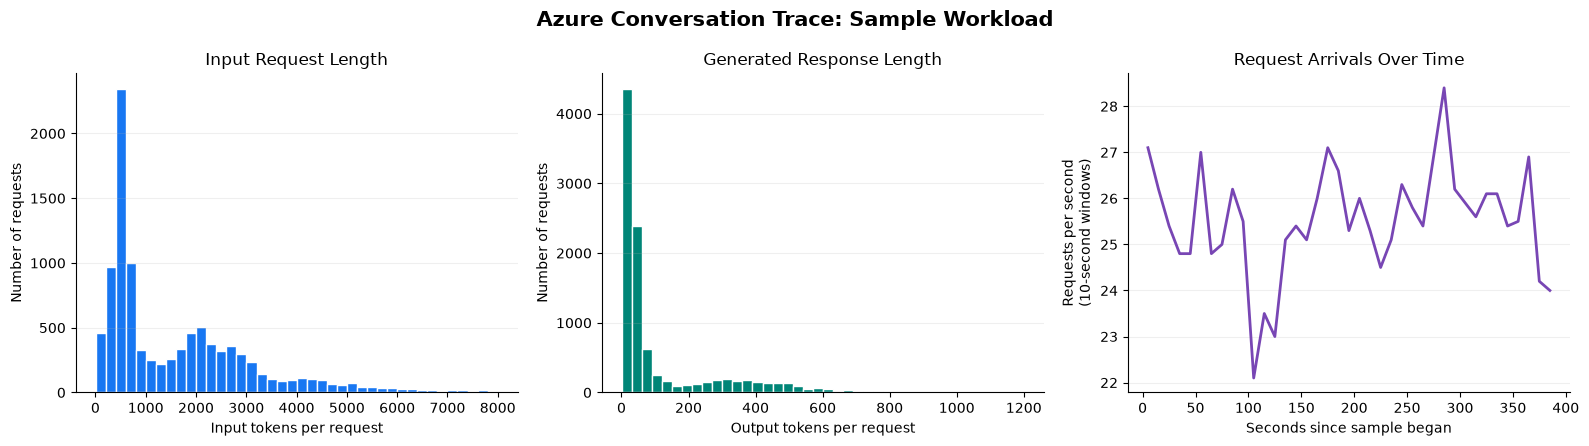

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(
    requests_df["ContextTokens"],
    bins=40, color="#1877F2", edgecolor="white"
)
axes[0].set_title("Input Request Length")
axes[0].set_xlabel("Input tokens per request")
axes[0].set_ylabel("Number of requests")

axes[1].hist(
    requests_df["GeneratedTokens"],
    bins=40, color="#008577", edgecolor="white"
)
axes[1].set_title("Generated Response Length")
axes[1].set_xlabel("Output tokens per request")
axes[1].set_ylabel("Number of requests")

# Use complete 10-second windows; exclude the partial final window.
window_seconds = 10
complete_windows = int(duration_seconds // window_seconds)

window_ids = (
    requests_df["arrival_seconds"] // window_seconds
).astype(int)

arrival_counts = (
    window_ids[window_ids < complete_windows]
    .value_counts()
    .reindex(range(complete_windows), fill_value=0)
    .sort_index()
)

axes[2].plot(
    (arrival_counts.index.to_numpy() + 0.5) * window_seconds,
    arrival_counts.to_numpy() / window_seconds,
    color="#7846B4", linewidth=2
)
axes[2].set_title("Request Arrivals Over Time")
axes[2].set_xlabel("Seconds since sample began")
axes[2].set_ylabel("Requests per second\n(10-second windows)")

for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Azure Conversation Trace: Sample Workload",
    fontsize=15, fontweight="bold"
)
fig.tight_layout()

fig.savefig(
    IMAGES_DIR / "azure_workload_exploration.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

### Processing-Time Profiles

I am using Vidur’s published A100 profiles for Meta’s Llama 3 8B model. These files contain computation timings that will inform the simulation, rather than measured end-to-end response times. I have pinned the source to a specific repository version so the same files can be retrieved again.

In [7]:
VIDUR_COMMIT = "abae7f63aa857300f5cdc6f5e0d27860cd24721b"

VIDUR_BASE_URL = (
    f"https://raw.githubusercontent.com/microsoft/vidur/{VIDUR_COMMIT}/"
    "data/profiling/compute/a100/meta-llama/Meta-Llama-3-8B"
)

profiles = {}

for profile_name in ["mlp", "attention"]:
    local_path = DATA_DIR / f"vidur_a100_llama3_8b_{profile_name}.csv"

    if local_path.exists():
        profile_df = pd.read_csv(local_path)
        print(f"Loaded saved {profile_name} profile.")
    else:
        print(f"Downloading {profile_name} profile...")
        profile_url = f"{VIDUR_BASE_URL}/{profile_name}.csv"
        request = Request(
            profile_url,
            headers={"User-Agent": "Mozilla/5.0"}
        )

        with urlopen(request, timeout=60) as response:
            profile_df = pd.read_csv(response)

        if profile_df.empty:
            raise ValueError(f"The {profile_name} profile is empty.")

        profile_df.to_csv(local_path, index=False)

    profiles[profile_name] = profile_df

    print(f"Rows: {len(profile_df):,}")
    print("Columns:")
    print(profile_df.columns.tolist())
    display(profile_df.head(3))
    print()

Rows: 1,824
Columns:
['time_stats.emb.min', 'time_stats.emb.max', 'time_stats.emb.mean', 'time_stats.emb.median', 'time_stats.emb.std', 'time_stats.input_layernorm.min', 'time_stats.input_layernorm.max', 'time_stats.input_layernorm.mean', 'time_stats.input_layernorm.median', 'time_stats.input_layernorm.std', 'time_stats.attn_pre_proj.min', 'time_stats.attn_pre_proj.max', 'time_stats.attn_pre_proj.mean', 'time_stats.attn_pre_proj.median', 'time_stats.attn_pre_proj.std', 'time_stats.attn_rope.min', 'time_stats.attn_rope.max', 'time_stats.attn_rope.mean', 'time_stats.attn_rope.median', 'time_stats.attn_rope.std', 'time_stats.attn_post_proj.min', 'time_stats.attn_post_proj.max', 'time_stats.attn_post_proj.mean', 'time_stats.attn_post_proj.median', 'time_stats.attn_post_proj.std', 'time_stats.post_attention_layernorm.min', 'time_stats.post_attention_layernorm.max', 'time_stats.post_attention_layernorm.mean', 'time_stats.post_attention_layernorm.median', 'time_stats.post_attention_layernorm.

,time_stats.emb.min,time_stats.emb.max,time_stats.emb.mean,time_stats.emb.median,time_stats.emb.std,time_stats.input_layernorm.min,time_stats.input_layernorm.max,time_stats.input_layernorm.mean,time_stats.input_layernorm.median,time_stats.input_layernorm.std,...,time_stats.add.median,time_stats.add.std,n_head,n_kv_head,n_embd,n_expanded_embd,vocab_size,use_gated_mlp,num_tokens,num_tensor_parallel_workers
0,1.784,2.022,1.963048,1.963,0.060780,0.752,0.850,0.8297,0.8255,0.020993,...,0.471,0.000805,32,8,4096,14336,128256,True,32768,1
1,1.824,2.047,1.982095,1.995,0.056296,0.766,0.865,0.8374,0.8395,0.020507,...,0.471,0.000829,32,8,4096,14336,128256,True,32768,1
2,1.740,1.999,1.936095,1.949,0.065618,0.732,0.835,0.8183,0.8210,0.021053,...,0.467,0.000726,32,8,4096,14336,128256,True,32512,1



Rows: 42,587
Columns:
['time_stats.attn_input_reshape.min', 'time_stats.attn_input_reshape.max', 'time_stats.attn_input_reshape.mean', 'time_stats.attn_input_reshape.median', 'time_stats.attn_input_reshape.std', 'time_stats.attn_kv_cache_save.min', 'time_stats.attn_kv_cache_save.max', 'time_stats.attn_kv_cache_save.mean', 'time_stats.attn_kv_cache_save.median', 'time_stats.attn_kv_cache_save.std', 'time_stats.attn_prefill.min', 'time_stats.attn_prefill.max', 'time_stats.attn_prefill.mean', 'time_stats.attn_prefill.median', 'time_stats.attn_prefill.std', 'time_stats.attn_decode.min', 'time_stats.attn_decode.max', 'time_stats.attn_decode.mean', 'time_stats.attn_decode.median', 'time_stats.attn_decode.std', 'time_stats.attn_output_reshape.min', 'time_stats.attn_output_reshape.max', 'time_stats.attn_output_reshape.mean', 'time_stats.attn_output_reshape.median', 'time_stats.attn_output_reshape.std', 'n_embd', 'n_q_head', 'n_kv_head', 'block_size', 'num_tensor_parallel_workers', 'max_model_

,time_stats.attn_input_reshape.min,time_stats.attn_input_reshape.max,time_stats.attn_input_reshape.mean,time_stats.attn_input_reshape.median,time_stats.attn_input_reshape.std,time_stats.attn_kv_cache_save.min,time_stats.attn_kv_cache_save.max,time_stats.attn_kv_cache_save.mean,time_stats.attn_kv_cache_save.median,time_stats.attn_kv_cache_save.std,...,n_q_head,n_kv_head,block_size,num_tensor_parallel_workers,max_model_len,batch_size,prefill_chunk_size,kv_cache_size,is_prefill,attention_backend
0,0.0,0.0,0.0,0.0,0.0,0.019,0.019,0.019,0.019,0.0,...,32,8,16,1,16384,1,64,0,True,AttentionBackend.FLASHINFER
1,0.0,0.0,0.0,0.0,0.0,0.019,0.019,0.019,0.019,0.0,...,32,8,16,1,16384,1,64,64,True,AttentionBackend.FLASHINFER
2,0.0,0.0,0.0,0.0,0.0,0.019,0.019,0.019,0.019,0.0,...,32,8,16,1,16384,1,64,128,True,AttentionBackend.FLASHINFER


In [8]:
# Inspect the available settings before building the simulation.
mlp_df = profiles["mlp"].copy()
attention_df = profiles["attention"].copy()

for name, profile in profiles.items():
    print(f"\n{name.upper()} PROFILE")
    print(f"Rows: {len(profile):,}")
    print(f"Missing cells: {profile.isna().sum().sum():,}")
    print(f"Exact duplicate rows: {profile.duplicated().sum():,}")

    timing_columns = [
        column for column in profile.columns
        if column.endswith(".median")
    ]

    timing_values = profile[timing_columns].to_numpy(dtype=float)
    print("Median timings are finite:", np.isfinite(timing_values).all())
    print("Median timings are nonnegative:", (timing_values >= 0).all())

print("\nMLP PROFILE SETTINGS")
for column in ["num_tensor_parallel_workers", "num_tokens"]:
    values = sorted(mlp_df[column].dropna().unique())
    print(f"{column}: {values}")

print("\nATTENTION PROFILE SETTINGS")
for column in [
    "num_tensor_parallel_workers",
    "attention_backend",
    "is_prefill",
    "batch_size",
    "prefill_chunk_size",
    "kv_cache_size",
]:
    values = sorted(attention_df[column].dropna().unique())
    print(f"{column}: {values}")

print("\nATTENTION ROWS BY CONFIGURATION")
display(
    attention_df.groupby(
        ["num_tensor_parallel_workers", "attention_backend", "is_prefill"],
        dropna=False,
    ).size().rename("profile_rows").reset_index()
)


MLP PROFILE
Rows: 1,824
Missing cells: 0
Exact duplicate rows: 0
Median timings are finite: True
Median timings are nonnegative: True

ATTENTION PROFILE
Rows: 42,587
Missing cells: 0
Exact duplicate rows: 63
Median timings are finite: True
Median timings are nonnegative: True

MLP PROFILE SETTINGS
num_tensor_parallel_workers: [np.int64(1), np.int64(2), np.int64(4), np.int64(8)]
num_tokens: [np.int64(1), np.int64(2), np.int64(4), np.int64(8), np.int64(16), np.int64(24), np.int64(32), np.int64(40), np.int64(48), np.int64(56), np.int64(64), np.int64(72), np.int64(80), np.int64(88), np.int64(96), np.int64(104), np.int64(112), np.int64(120), np.int64(128), np.int64(136), np.int64(144), np.int64(152), np.int64(160), np.int64(168), np.int64(176), np.int64(184), np.int64(192), np.int64(200), np.int64(208), np.int64(216), np.int64(224), np.int64(232), np.int64(240), np.int64(248), np.int64(256), np.int64(264), np.int64(272), np.int64(280), np.int64(288), np.int64(296), np.int64(304), np.int64(

,num_tensor_parallel_workers,attention_backend,is_prefill,profile_rows
0,1,AttentionBackend.FLASHINFER,False,15960
1,1,AttentionBackend.FLASHINFER,True,2648
2,4,AttentionBackend.FLASHINFER,False,21331
3,4,AttentionBackend.FLASHINFER,True,2648


### Preparing the Performance Profiles

Both performance profiles passed the missing-value and timing checks.
The attention profile contained 63 exact duplicate rows, which I removed
from the working copy while keeping the original downloaded file.

I use profiles with one tensor-parallel worker to keep the analysis
focused on a single A100 GPU. The attention backend stays fixed as
FlashInfer, so changes in the results reflect the batching settings
rather than a change in hardware or backend.

I keep prompt processing (prefill) and token generation (decode)
separate because they represent different stages of a response.
These profiles will inform the simulation; they are not measurements
of Meta's production service.

In [9]:
# Keep the original downloads unchanged.
mlp_clean = mlp_df.drop_duplicates().copy()
attention_clean = attention_df.drop_duplicates().copy()

# Fix the hardware configuration at one tensor-parallel worker.
mlp_single = mlp_clean.loc[
    mlp_clean["num_tensor_parallel_workers"].eq(1)
].copy()

attention_single = attention_clean.loc[
    attention_clean["num_tensor_parallel_workers"].eq(1)
    & attention_clean["attention_backend"].eq("AttentionBackend.FLASHINFER")
].copy()

# Handle boolean values consistently, including when CSVs are reloaded.
prefill_flag = (
    attention_single["is_prefill"]
    .astype(str)
    .str.strip()
    .str.lower()
)
assert prefill_flag.isin(["true", "false"]).all(), "Unexpected prefill flag."

prefill_profile = attention_single.loc[prefill_flag.eq("true")].copy()
decode_profile = attention_single.loc[prefill_flag.eq("false")].copy()

assert not mlp_single.empty, "No single-GPU MLP profiles found."
assert not prefill_profile.empty, "No single-GPU prefill profiles found."
assert not decode_profile.empty, "No single-GPU decode profiles found."

# Save the selected profiles for reproducibility.
mlp_single.to_csv(DATA_DIR / "mlp_single_gpu.csv", index=False)
prefill_profile.to_csv(DATA_DIR / "attention_prefill_single_gpu.csv", index=False)
decode_profile.to_csv(DATA_DIR / "attention_decode_single_gpu.csv", index=False)

print("Selected profile rows:")
print(f"MLP: {len(mlp_single):,}")
print(f"Prefill: {len(prefill_profile):,}")
print(f"Decode: {len(decode_profile):,}")

# Compact summaries avoid printing hundreds of individual values.
print("\nMLP token coverage:")
display(mlp_single[["num_tokens"]].agg(["min", "max", "nunique"]))

for name, profile in [
    ("Prefill", prefill_profile),
    ("Decode", decode_profile),
]:
    print(f"\n{name} coverage:")
    display(
        profile[["batch_size", "prefill_chunk_size", "kv_cache_size"]]
        .agg(["min", "max", "nunique"])
    )

Selected profile rows:
MLP: 456
Prefill: 2,644
Decode: 15,957

MLP token coverage:


,num_tokens
min,1
max,32768
nunique,451



Prefill coverage:


,batch_size,prefill_chunk_size,kv_cache_size
min,1,32,0
max,1,16384,16320
nunique,1,178,584



Decode coverage:


,batch_size,prefill_chunk_size,kv_cache_size
min,1,0,32
max,512,0,16128
nunique,176,1,127


## 3. Building the Processing-Time Model

I use the selected A100 profiles to estimate processing time for
different batching configurations. The recorded timings are in
milliseconds.

When the same setting has multiple measurements, I use the median
timing. I keep prompt processing and token generation separate:
prefill processes the input prompt, while decode generates additional
tokens.

For a new prompt, I use prefill measurements with an empty KV cache.
The decode estimates account for both batch size and the amount of
previously processed context.

These measurements support a simplified simulation, not a full
reproduction of Vidur or Meta's production infrastructure.

In [10]:
# Organize component timings by the settings that affect them.
mlp_timing_columns = [
    column for column in mlp_single.columns
    if column.endswith(".median")
]

mlp_lookup = (
    mlp_single
    .groupby("num_tokens")[mlp_timing_columns]
    .median()
    .sort_index()
)

# New prompts start without previously cached context.
prefill_lookup = (
    prefill_profile.loc[prefill_profile["kv_cache_size"].eq(0)]
    .groupby("prefill_chunk_size")["time_stats.attn_prefill.median"]
    .median()
    .sort_index()
)

decode_lookup = (
    decode_profile
    .groupby(["batch_size", "kv_cache_size"])[
        "time_stats.attn_decode.median"
    ]
    .median()
    .sort_index()
)

assert not prefill_lookup.empty, "No empty-cache prefill measurements found."
assert (prefill_lookup > 0).all(), "Check nonpositive prefill timings."
assert (decode_lookup > 0).all(), "Check nonpositive decode timings."

# Save the organized measurements.
mlp_lookup.to_csv(DATA_DIR / "mlp_timing_lookup.csv")
prefill_lookup.to_csv(DATA_DIR / "prefill_timing_lookup.csv")
decode_lookup.to_csv(DATA_DIR / "decode_timing_lookup.csv")

print(f"MLP lookup: {len(mlp_lookup):,} token settings")
print(f"Prefill lookup: {len(prefill_lookup):,} prompt-length settings")
print(f"Decode lookup: {len(decode_lookup):,} batch/context settings")

coverage = pd.DataFrame({
    "Measurement": [
        "MLP tokens",
        "New-prompt prefill tokens",
        "Decode batch size",
        "Decode context tokens",
    ],
    "Minimum": [
        mlp_lookup.index.min(),
        prefill_lookup.index.min(),
        decode_lookup.index.get_level_values("batch_size").min(),
        decode_lookup.index.get_level_values("kv_cache_size").min(),
    ],
    "Maximum": [
        mlp_lookup.index.max(),
        prefill_lookup.index.max(),
        decode_lookup.index.get_level_values("batch_size").max(),
        decode_lookup.index.get_level_values("kv_cache_size").max(),
    ],
})

display(coverage)

MLP lookup: 451 token settings
Prefill lookup: 178 prompt-length settings
Decode lookup: 15,572 batch/context settings


,Measurement,Minimum,Maximum
0,MLP tokens,1,32768
1,New-prompt prefill tokens,32,16384
2,Decode batch size,1,512
3,Decode context tokens,32,16128


### Timing Assumptions

I estimate processing time by combining the measured component timings
across Llama 3 8B's 32 transformer layers.

For values between measured settings, I use linear interpolation.
Prompts or contexts shorter than 32 tokens use the 32-token attention
timing. Values above the available profile range raise an error rather
than being silently estimated.

The simplified model processes each prompt separately and batches
token generation. Decode attention uses the average context length of
the active requests. These are modeling assumptions, not claims about
Meta's scheduling system.

The estimates exclude network delay, CPU scheduling overhead,
embedding computation, and the final output layer. The resulting
response times will therefore be approximate.

In [11]:
NUM_LAYERS = 32

# Transformer-block components; embedding is excluded.
block_components = [
    "input_layernorm", "attn_pre_proj", "attn_rope",
    "attn_post_proj", "post_attention_layernorm",
    "mlp_up_proj", "mlp_act", "mlp_down_proj", "add",
]
block_columns = [f"time_stats.{name}.median" for name in block_components]
block_lookup = mlp_lookup[block_columns].sum(axis=1)

# Include the attention-stage operations for each processing mode.
attention_overheads = [
    "time_stats.attn_input_reshape.median",
    "time_stats.attn_kv_cache_save.median",
    "time_stats.attn_output_reshape.median",
]

prefill_work = prefill_profile.loc[
    prefill_profile["kv_cache_size"].eq(0)
].copy()
prefill_work["attention_ms"] = prefill_work[
    attention_overheads + ["time_stats.attn_prefill.median"]
].sum(axis=1)

prefill_attention = (
    prefill_work.groupby("prefill_chunk_size")["attention_ms"]
    .median().sort_index()
)

decode_work = decode_profile.copy()
decode_work["attention_ms"] = decode_work[
    attention_overheads + ["time_stats.attn_decode.median"]
].sum(axis=1)

decode_attention = (
    decode_work.groupby(["batch_size", "kv_cache_size"])["attention_ms"]
    .median().sort_index()
)

# Prepare one context-length curve for each measured batch size.
decode_curves = {
    int(batch): curve.droplevel("batch_size").sort_index()
    for batch, curve in decode_attention.groupby(level="batch_size")
}


def interpolate_timing(value, curve, allow_lower_boundary=False):
    """Interpolate measured timings without extrapolating above the range."""
    value = float(value)
    x = curve.index.to_numpy(dtype=float)
    y = curve.to_numpy(dtype=float)

    if not np.isfinite(value) or value <= 0:
        raise ValueError("Timing inputs must be finite and positive.")

    if value < x[0]:
        if allow_lower_boundary:
            value = x[0]
        else:
            raise ValueError(f"{value} is below the measured minimum {x[0]}.")

    if value > x[-1]:
        raise ValueError(f"{value} exceeds the measured maximum {x[-1]}.")

    return float(np.interp(value, x, y))


def prefill_time_ms(input_tokens):
    """Estimate transformer processing time for one new prompt."""
    block_ms = interpolate_timing(input_tokens, block_lookup)
    attention_ms = interpolate_timing(
        input_tokens, prefill_attention, allow_lower_boundary=True
    )
    return NUM_LAYERS * (block_ms + attention_ms)


def decode_step_ms(context_lengths):
    """Estimate one generation step for all currently active requests."""
    contexts = np.asarray(context_lengths, dtype=float)

    if contexts.ndim != 1 or contexts.size == 0:
        raise ValueError("Provide a nonempty list of context lengths.")
    if not np.isfinite(contexts).all() or (contexts <= 0).any():
        raise ValueError("Context lengths must be finite and positive.")

    batch_size = len(contexts)
    if batch_size not in decode_curves:
        raise ValueError(f"No measured decode curve for batch {batch_size}.")

    block_ms = interpolate_timing(batch_size, block_lookup)
    attention_ms = interpolate_timing(
        contexts.mean(),
        decode_curves[batch_size],
        allow_lower_boundary=True,
    )
    return NUM_LAYERS * (block_ms + attention_ms)


# Check representative inputs before using the functions in a simulation.
timing_checks = pd.DataFrame({
    "Operation": [
        "Prefill: 32-token prompt",
        "Prefill: 1,024-token prompt",
        "Prefill: 4,096-token prompt",
        "Decode: 1 request, 1,024-token context",
        "Decode: 8 requests, 1,024-token contexts",
    ],
    "Estimated time (ms)": [
        prefill_time_ms(32),
        prefill_time_ms(1024),
        prefill_time_ms(4096),
        decode_step_ms([1024]),
        decode_step_ms([1024] * 8),
    ],
})

assert np.isfinite(timing_checks["Estimated time (ms)"]).all()
assert (timing_checks["Estimated time (ms)"] > 0).all()
display(timing_checks.round(3))

,Operation,Estimated time (ms)
0,Prefill: 32-token prompt,11.584
1,"Prefill: 1,024-token prompt",96.032
2,"Prefill: 4,096-token prompt",376.560
3,"Decode: 1 request, 1,024-token context",10.544
4,"Decode: 8 requests, 1,024-token contexts",11.296


## 4. Simulating Request Processing

The simulation processes requests in arrival order. A batch starts
when it reaches the maximum batch size or the oldest request reaches
its batching-wait limit, provided the GPU is available.

Each prompt is processed separately. Its first token becomes available
when prefill finishes. The remaining tokens are generated in batches,
and requests leave the active batch when their responses are complete.
A new batch starts after the current batch finishes.

Time to first token includes queueing, intentional batching delay,
and prompt processing. The batching-wait limit does not cap total
queueing time when the GPU is busy.

This is a simplified static-batching model. It does not implement
continuous batching, where new requests can join an active batch.

The initial check measures throughput over a finite workload.
That alone does not establish sustainable capacity; queue growth
must also be examined.

In [12]:
def simulate_requests(workload, max_batch_size, max_wait_ms):
    """Replay arrivals using static batches and profile-based timings."""
    if max_batch_size < 1 or int(max_batch_size) != max_batch_size:
        raise ValueError("Batch size must be a positive integer.")
    if not np.isfinite(max_wait_ms) or max_wait_ms < 0:
        raise ValueError("Batching wait must be finite and nonnegative.")

    max_batch_size = int(max_batch_size)
    missing_sizes = set(range(1, max_batch_size + 1)) - set(decode_curves)
    if missing_sizes:
        raise ValueError(f"Missing decode batch sizes: {sorted(missing_sizes)}")

    arrivals = workload["arrival_seconds"].to_numpy(dtype=float) * 1000
    inputs = workload["ContextTokens"].to_numpy(dtype=int)
    outputs = workload["GeneratedTokens"].to_numpy(dtype=int)
    n = len(workload)

    if n == 0:
        raise ValueError("The workload is empty.")
    if not np.isfinite(arrivals).all() or (np.diff(arrivals) < 0).any():
        raise ValueError("Arrivals must be finite and sorted.")
    if (inputs <= 0).any() or (outputs <= 0).any():
        raise ValueError("Token counts must be positive.")

    first_token = np.full(n, np.nan)
    completion = np.full(n, np.nan)
    batch_start = np.full(n, np.nan)
    batch_sizes = []

    clock_ms = arrivals[0]
    next_request = 0

    while next_request < n:
        # Start immediately if the GPU is free and the batch is full.
        # Otherwise wait until the oldest request's deadline.
        ready_ms = max(clock_ms, arrivals[next_request])
        full_index = next_request + max_batch_size - 1
        full_ms = arrivals[full_index] if full_index < n else np.inf
        deadline_ms = arrivals[next_request] + max_wait_ms
        start_ms = max(ready_ms, min(full_ms, deadline_ms))

        available_end = np.searchsorted(arrivals, start_ms, side="right")
        end = min(next_request + max_batch_size, available_end)
        ids = np.arange(next_request, end)

        assert len(ids) > 0
        batch_sizes.append(len(ids))
        batch_start[ids] = start_ms
        clock_ms = start_ms

        # Prefill produces each request's first output token.
        for request_id in ids:
            clock_ms += prefill_time_ms(inputs[request_id])
            first_token[request_id] = clock_ms
            if outputs[request_id] == 1:
                completion[request_id] = clock_ms

        remaining = outputs[ids] - 1
        contexts = inputs[ids] + 1

        # Completed requests leave the decode batch.
        while (remaining > 0).any():
            active = remaining > 0
            clock_ms += decode_step_ms(contexts[active])
            remaining[active] -= 1
            contexts[active] += 1
            just_finished = active & (remaining == 0)
            completion[ids[just_finished]] = clock_ms

        next_request = end

    assert np.isfinite(first_token).all()
    assert np.isfinite(completion).all()
    assert (first_token >= arrivals).all()
    assert (completion >= first_token).all()

    ttft = first_token - arrivals
    queue_and_batch_wait = batch_start - arrivals
    elapsed_seconds = (completion.max() - arrivals[0]) / 1000
    quarter = max(1, n // 4)

    return {
        "max_batch_size": max_batch_size,
        "max_wait_ms": max_wait_ms,
        "requests_completed": n,
        "observed_throughput_rps": n / elapsed_seconds,
        "p95_ttft_ms": np.percentile(ttft, 95),
        "mean_actual_batch_size": np.mean(batch_sizes),
        "early_mean_wait_ms": queue_and_batch_wait[:quarter].mean(),
        "late_mean_wait_ms": queue_and_batch_wait[-quarter:].mean(),
    }


# Small diagnostic run using the same requests for each configuration.
pilot_workload = requests_df.iloc[:200].copy()

pilot_results = pd.DataFrame([
    simulate_requests(pilot_workload, max_batch_size=1, max_wait_ms=0),
    simulate_requests(pilot_workload, max_batch_size=8, max_wait_ms=0),
    simulate_requests(pilot_workload, max_batch_size=8, max_wait_ms=50),
])

display(pilot_results.round(3))

,max_batch_size,max_wait_ms,requests_completed,observed_throughput_rps,p95_ttft_ms,mean_actual_batch_size,early_mean_wait_ms,late_mean_wait_ms
0,1,0,200,0.769,240021.366,1.000,25643.748,223946.440
1,8,0,200,1.415,125297.861,7.143,11271.775,114420.149
2,8,50,200,1.431,126186.601,7.407,11550.917,114876.579


### Initial Simulation Findings

The initial simulation showed substantial queue growth. With a maximum
batch size of eight and no intentional batching wait, average waiting
time increased from about 11.3 seconds for early requests to 114.4 seconds
for late requests.

Batching improved throughput compared with processing one request at
a time, but the simulated service could not keep up with the original
arrival stream.

I next test lower arrival rates by spacing the same requests farther
apart. Their order and token counts stay unchanged. This will help
identify the load the simplified model can handle without persistent
queue growth. A finite simulation provides an estimate, not proof
of long-term stability.

In [13]:
def rescale_arrivals(workload, target_rate_rps):
    """Change arrival spacing while preserving order and token counts."""
    if not np.isfinite(target_rate_rps) or target_rate_rps <= 0:
        raise ValueError("Target arrival rate must be finite and positive.")
    if len(workload) < 2:
        raise ValueError("At least two requests are required.")

    scaled = workload.copy()
    elapsed = (
        scaled["arrival_seconds"] - scaled["arrival_seconds"].iloc[0]
    )
    duration = float(elapsed.iloc[-1])

    if duration <= 0:
        raise ValueError("The workload must cover a positive time interval.")

    original_rate = (len(scaled) - 1) / duration
    scaled["arrival_seconds"] = elapsed * original_rate / target_rate_rps

    # TIMESTAMP remains the original source timestamp.
    # The simulation uses the rescaled arrival_seconds column.
    return scaled


# A larger diagnostic sample, held constant across arrival-rate tests.
capacity_workload = requests_df.iloc[:500].copy()
load_checks = []

for arrival_rate in [0.5, 1.0, 2.0]:
    scaled_workload = rescale_arrivals(capacity_workload, arrival_rate)

    result = simulate_requests(
        scaled_workload,
        max_batch_size=8,
        max_wait_ms=50,
    )
    result["offered_load_rps"] = arrival_rate
    result["wait_change_ms"] = (
        result["late_mean_wait_ms"] - result["early_mean_wait_ms"]
    )
    load_checks.append(result)
    print(f"Finished testing {arrival_rate:.1f} requests/second.")

load_check_df = pd.DataFrame(load_checks)

display(load_check_df[[
    "offered_load_rps",
    "observed_throughput_rps",
    "p95_ttft_ms",
    "mean_actual_batch_size",
    "early_mean_wait_ms",
    "late_mean_wait_ms",
    "wait_change_ms",
]].round(3))

Finished testing 0.5 requests/second.
Finished testing 1.0 requests/second.
Finished testing 2.0 requests/second.


,offered_load_rps,observed_throughput_rps,p95_ttft_ms,mean_actual_batch_size,early_mean_wait_ms,late_mean_wait_ms,wait_change_ms
0,0.5,0.501,5941.764,1.724,1415.465,1362.204,-53.261
1,1.0,0.990,12514.153,3.226,2248.754,2163.561,-85.193
2,2.0,1.413,89695.207,7.353,11422.326,86080.622,74658.296


## 5. Evaluating Batching Configurations

I compare 50 combinations of maximum batch size and maximum batching
wait. Each configuration uses the same 500 requests, preserving their
order and token counts.

For each configuration, I test several arrival rates. A rate passes
the initial capacity screen when:

- Completed throughput is at least 98% of the offered arrival rate.
- The increase in average waiting time from the first quarter to the
  last quarter is no more than 1% of the arrival period.

These thresholds are explicit modeling choices that allow some
finite-sample variation. Passing this screen does not prove long-term
queue stability.

The estimated supported rate is the highest tested rate that passes.
I pair it with the p95 time to first token measured at that same rate.
This compares each configuration near its estimated supported load,
rather than comparing response times at a common arrival rate.

The rate grid limits the precision of these estimates. Results that
reach the highest tested rate will be flagged for further testing.

In [14]:
from itertools import product
from time import perf_counter

BATCH_SIZES = [1, 2, 4, 8, 16]
WAIT_LIMITS_MS = [0, 10, 25, 50, 100, 200, 350, 500, 750, 1000]
TEST_RATES_RPS = [0.10, 0.25, 0.50, 0.75, 1.00, 1.25, 1.50, 2.00, 3.00]

analysis_workload = requests_df.iloc[:500].copy()

# Prepare identical workloads at each tested arrival rate once.
scaled_workloads = {
    rate: rescale_arrivals(analysis_workload, rate)
    for rate in TEST_RATES_RPS
}

configurations = list(product(BATCH_SIZES, WAIT_LIMITS_MS))
configuration_results = []
load_test_results = []
started = perf_counter()

for number, (batch_size, wait_ms) in enumerate(configurations, start=1):
    config_id = f"C{number:03d}"
    passing_results = []

    for rate in TEST_RATES_RPS:
        workload = scaled_workloads[rate]
        result = simulate_requests(workload, batch_size, wait_ms)

        arrival_period_ms = (
            workload["arrival_seconds"].iloc[-1]
            - workload["arrival_seconds"].iloc[0]
        ) * 1000

        wait_growth_ms = (
            result["late_mean_wait_ms"] - result["early_mean_wait_ms"]
        )
        throughput_ratio = result["observed_throughput_rps"] / rate
        growth_fraction = wait_growth_ms / arrival_period_ms

        passes = (
            throughput_ratio >= 0.98
            and growth_fraction <= 0.01
        )

        result.update({
            "config_id": config_id,
            "offered_load_rps": rate,
            "throughput_ratio": throughput_ratio,
            "wait_growth_fraction": growth_fraction,
            "passes_capacity_screen": passes,
        })
        load_test_results.append(result.copy())

        if passes:
            passing_results.append(result.copy())

    if passing_results:
        selected = max(
            passing_results,
            key=lambda row: row["offered_load_rps"],
        )
        configuration_results.append({
            "config_id": config_id,
            "max_batch_size": batch_size,
            "max_wait_ms": wait_ms,
            "estimated_supported_rate_rps": selected["offered_load_rps"],
            "p95_ttft_ms": selected["p95_ttft_ms"],
            "observed_throughput_rps": selected["observed_throughput_rps"],
            "mean_actual_batch_size": selected["mean_actual_batch_size"],
            "upper_rate_boundary": (
                selected["offered_load_rps"] == max(TEST_RATES_RPS)
            ),
            "capacity_estimate_found": True,
        })
    else:
        configuration_results.append({
            "config_id": config_id,
            "max_batch_size": batch_size,
            "max_wait_ms": wait_ms,
            "estimated_supported_rate_rps": np.nan,
            "p95_ttft_ms": np.nan,
            "observed_throughput_rps": np.nan,
            "mean_actual_batch_size": np.nan,
            "upper_rate_boundary": False,
            "capacity_estimate_found": False,
        })

    # Checkpoints preserve completed work during a longer run.
    pd.DataFrame(configuration_results).to_csv(
        DATA_DIR / "configuration_results.csv", index=False
    )
    pd.DataFrame(load_test_results).to_csv(
        DATA_DIR / "capacity_load_tests.csv", index=False
    )

    elapsed = perf_counter() - started
    print(
        f"{number}/{len(configurations)} complete | "
        f"batch={batch_size}, wait={wait_ms} ms | "
        f"elapsed={elapsed / 60:.1f} min",
        flush=True,
    )

results_df = pd.DataFrame(configuration_results)
load_tests_df = pd.DataFrame(load_test_results)

print("\nConfigurations evaluated:", len(results_df))
print("Capacity estimates found:", results_df["capacity_estimate_found"].sum())
print("At upper rate boundary:", results_df["upper_rate_boundary"].sum())

display(results_df.head(10).round(3))

1/50 complete | batch=1, wait=0 ms | elapsed=0.2 min
2/50 complete | batch=1, wait=10 ms | elapsed=0.4 min
3/50 complete | batch=1, wait=25 ms | elapsed=0.7 min
4/50 complete | batch=1, wait=50 ms | elapsed=0.9 min
5/50 complete | batch=1, wait=100 ms | elapsed=1.1 min
6/50 complete | batch=1, wait=200 ms | elapsed=1.3 min
7/50 complete | batch=1, wait=350 ms | elapsed=1.5 min
8/50 complete | batch=1, wait=500 ms | elapsed=1.7 min
9/50 complete | batch=1, wait=750 ms | elapsed=2.0 min
10/50 complete | batch=1, wait=1000 ms | elapsed=2.2 min
11/50 complete | batch=2, wait=0 ms | elapsed=2.4 min
12/50 complete | batch=2, wait=10 ms | elapsed=2.6 min
13/50 complete | batch=2, wait=25 ms | elapsed=2.8 min
14/50 complete | batch=2, wait=50 ms | elapsed=3.0 min
15/50 complete | batch=2, wait=100 ms | elapsed=3.2 min
16/50 complete | batch=2, wait=200 ms | elapsed=3.4 min
17/50 complete | batch=2, wait=350 ms | elapsed=3.6 min
18/50 complete | batch=2, wait=500 ms | elapsed=3.8 min
19/50 comp

,config_id,max_batch_size,max_wait_ms,estimated_supported_rate_rps,p95_ttft_ms,observed_throughput_rps,mean_actual_batch_size,upper_rate_boundary,capacity_estimate_found
0,C001,1,0,0.5,15874.972,0.5,1.0,False,True
1,C002,1,10,0.5,15874.972,0.5,1.0,False,True
2,C003,1,25,0.5,15874.972,0.5,1.0,False,True
3,C004,1,50,0.5,15874.972,0.5,1.0,False,True
4,C005,1,100,0.5,15874.972,0.5,1.0,False,True
5,C006,1,200,0.5,15874.972,0.5,1.0,False,True
6,C007,1,350,0.5,15874.972,0.5,1.0,False,True
7,C008,1,500,0.5,15874.972,0.5,1.0,False,True
8,C009,1,750,0.5,15874.972,0.5,1.0,False,True
9,C010,1,1000,0.5,15874.972,0.5,1.0,False,True


## 6. Identifying Efficient Configurations

All 50 configurations produced an estimated supported arrival rate.
None reached the upper boundary of the tested rate grid.

The batch-size-one configurations produced identical results because
a single request immediately fills the batch. There is no reason to
wait for additional requests.

I identify efficient configurations using two objectives:
- Maximize estimated supported requests per second.
- Minimize p95 time to first token at that supported rate.

A configuration is dominated when another configuration supports at
least as many requests per second with no greater response delay,
and is strictly better on at least one objective.

Configurations with identical objective values do not dominate each
other. Efficiency is assessed within the tested configurations and
the assumptions of this simulation.

In [15]:
RATE_COLUMN = "estimated_supported_rate_rps"
DELAY_COLUMN = "p95_ttft_ms"
OBJECTIVE_COLUMNS = [RATE_COLUMN, DELAY_COLUMN]

# Validate the final configuration dataset.
assert len(results_df) == 50
assert results_df["config_id"].is_unique
assert not results_df.duplicated(
    ["max_batch_size", "max_wait_ms"]
).any()
assert results_df["capacity_estimate_found"].all()
assert np.isfinite(results_df[OBJECTIVE_COLUMNS].to_numpy()).all()
assert (results_df[OBJECTIVE_COLUMNS] > 0).all().all()
assert (
    results_df["mean_actual_batch_size"]
    <= results_df["max_batch_size"]
).all()

print("Configuration validation passed.")
display(results_df[
    ["max_batch_size", "max_wait_ms"] + OBJECTIVE_COLUMNS
].describe().round(3))


def is_pareto_optimal(objectives, maximize):
    """
    Return a Boolean mask identifying nondominated rows.

    A dominates B when A is at least as good on every objective
    and strictly better on at least one. Identical rows are retained.

    Time complexity: O(n² × number of objectives).
    """
    values = np.asarray(objectives, dtype=float)
    directions = np.asarray(maximize, dtype=bool)

    if values.ndim != 2:
        raise ValueError("Objectives must be a two-dimensional array.")
    if directions.shape != (values.shape[1],):
        raise ValueError("Provide one direction per objective.")
    if not np.isfinite(values).all():
        raise ValueError("Objectives must contain only finite values.")

    # Convert minimization objectives so that larger always means better.
    benefits = values * np.where(directions, 1.0, -1.0)
    efficient = np.ones(len(values), dtype=bool)

    for i, candidate in enumerate(benefits):
        at_least_as_good = np.all(benefits >= candidate, axis=1)
        strictly_better = np.any(benefits > candidate, axis=1)
        efficient[i] = not np.any(at_least_as_good & strictly_better)

    return efficient


# Check mixed directions, identical points, and a dominated point.
test_points = np.array([
    [1.0, 100.0],
    [2.0, 200.0],
    [1.0, 200.0],
    [1.0, 100.0],
])
assert np.array_equal(
    is_pareto_optimal(test_points, maximize=[True, False]),
    [True, True, False, True],
)
assert is_pareto_optimal(
    np.empty((0, 2)), maximize=[True, False]
).size == 0
assert is_pareto_optimal(
    [[1.0, 100.0]], maximize=[True, False]
).all()

# Use full precision for comparisons; round only displayed results.
results_df["is_pareto"] = is_pareto_optimal(
    results_df[OBJECTIVE_COLUMNS].to_numpy(),
    maximize=[True, False],
)

frontier_df = results_df.loc[results_df["is_pareto"]].copy()
dominated_df = results_df.loc[~results_df["is_pareto"]].copy()

print("\nPareto checks passed.")
print(f"Total configurations: {len(results_df)}")
print(f"Efficient configurations: {len(frontier_df)}")
print(f"Dominated configurations: {len(dominated_df)}")
print(f"Percentage efficient: {100 * results_df['is_pareto'].mean():.1f}%")
print(
    "Distinct efficient objective pairs:",
    len(frontier_df.drop_duplicates(OBJECTIVE_COLUMNS)),
)

results_df.to_csv(DATA_DIR / "configuration_results.csv", index=False)
frontier_df.to_csv(DATA_DIR / "pareto_frontier.csv", index=False)

display(
    frontier_df[
        ["config_id", "max_batch_size", "max_wait_ms"] + OBJECTIVE_COLUMNS
    ].sort_values(OBJECTIVE_COLUMNS).round(3)
)

Configuration validation passed.


,max_batch_size,max_wait_ms,estimated_supported_rate_rps,p95_ttft_ms
count,50.000,50.000,50.000,50.000
mean,6.200,298.500,0.920,18124.969
std,5.511,334.603,0.274,7212.572
min,1.000,0.000,0.500,6855.601
25%,2.000,25.000,0.750,12481.538
50%,4.000,150.000,1.000,16376.185
75%,8.000,500.000,1.250,22398.530
max,16.000,1000.000,1.250,32678.372



Pareto checks passed.
Total configurations: 50
Efficient configurations: 2
Dominated configurations: 48
Percentage efficient: 4.0%
Distinct efficient objective pairs: 2


,config_id,max_batch_size,max_wait_ms,estimated_supported_rate_rps,p95_ttft_ms
49,C050,16,1000,1.00,6855.601
45,C046,16,200,1.25,8393.457


## 7. Examining Dominated Configurations

The analysis identified two efficient configurations out of 50.
C050 offers the shorter first-token delay, while C046 supports the
higher arrival rate. Neither is better on both objectives.

The other 48 configurations are dominated within the tested dataset.
For each dominated configuration, I identify an efficient alternative
that supports at least the same arrival rate with no greater delay,
and improves at least one objective.

These comparisons use response times measured at each configuration's
estimated supported rate.

In [16]:
# Find an efficient alternative for every dominated configuration.
comparison_rows = []

for _, candidate in dominated_df.iterrows():
    alternatives = frontier_df.loc[
        (frontier_df[RATE_COLUMN] >= candidate[RATE_COLUMN])
        & (frontier_df[DELAY_COLUMN] <= candidate[DELAY_COLUMN])
        & (
            (frontier_df[RATE_COLUMN] > candidate[RATE_COLUMN])
            | (frontier_df[DELAY_COLUMN] < candidate[DELAY_COLUMN])
        )
    ]

    assert not alternatives.empty, (
        f"No efficient alternative found for {candidate['config_id']}."
    )

    # Among dominating alternatives, choose the shortest response delay.
    alternative = alternatives.sort_values(
        [DELAY_COLUMN, RATE_COLUMN, "config_id"],
        ascending=[True, False, True],
    ).iloc[0]

    comparison_rows.append({
        "dominated_config": candidate["config_id"],
        "original_batch": candidate["max_batch_size"],
        "original_wait_ms": candidate["max_wait_ms"],
        "original_rate_rps": candidate[RATE_COLUMN],
        "original_p95_ms": candidate[DELAY_COLUMN],
        "efficient_alternative": alternative["config_id"],
        "alternative_batch": alternative["max_batch_size"],
        "alternative_wait_ms": alternative["max_wait_ms"],
        "alternative_rate_rps": alternative[RATE_COLUMN],
        "alternative_p95_ms": alternative[DELAY_COLUMN],
        "rate_gain_rps": alternative[RATE_COLUMN] - candidate[RATE_COLUMN],
        "p95_reduction_ms": candidate[DELAY_COLUMN] - alternative[DELAY_COLUMN],
        "p95_reduction_pct": (
            100 * (candidate[DELAY_COLUMN] - alternative[DELAY_COLUMN])
            / candidate[DELAY_COLUMN]
        ),
    })

dominance_examples_df = pd.DataFrame(comparison_rows)
dominance_examples_df.to_csv(
    DATA_DIR / "dominated_comparisons.csv", index=False
)

# Show examples from different original batch sizes.
examples_to_show = (
    dominance_examples_df
    .sort_values("p95_reduction_ms", ascending=False)
    .drop_duplicates("original_batch")
    .head(3)
)

print("Examples of improvements available within the tested configurations:")
display(examples_to_show.round(3))

Examples of improvements available within the tested configurations:


,dominated_config,original_batch,original_wait_ms,original_rate_rps,original_p95_ms,efficient_alternative,alternative_batch,alternative_wait_ms,alternative_rate_rps,alternative_p95_ms,rate_gain_rps,p95_reduction_ms,p95_reduction_pct
25,C026,4,200,1.00,32678.372,C050,16,1000,1.0,6855.601,0.00,25822.771,79.021
15,C016,2,200,0.75,27846.748,C050,16,1000,1.0,6855.601,0.25,20991.147,75.381
9,C010,1,1000,0.50,15874.972,C050,16,1000,1.0,6855.601,0.50,9019.371,56.815


## 8. Comparing Five Strategic Priorities

The dominated-point comparisons show substantial improvement opportunities.
For example, C050 supports the same estimated arrival rate as C026,
but reduces p95 first-token delay by about 79%.

I compare five strategies using only efficient configurations:

- **Balanced:** Maximize the sum of the normalized throughput and
  responsiveness scores, giving both objectives equal weight.
- **Equity:** Minimize the gap between those two scores.
  Here, equity means similar relative achievement across objectives,
  not fairness between individual users.
- **Throughput priority:** Maximize the estimated supported arrival rate.
- **Response-time priority:** Minimize p95 time to first token.
- **Custom weighted:** Give responsiveness 70% weight and throughput
  30%, reflecting a preference for shorter delays in an interactive service.

Normalization uses the minimum and maximum values across all 50
configurations. A higher responsiveness score means a shorter delay.
These scores depend on the tested ranges; they are not satisfaction
ratings or service-level guarantees.

There are only two efficient configurations, so several strategies may
select the same option. The custom weights express an analytical
preference, not a confirmed Meta policy.

In [17]:
# Normalize across all tested configurations.
rate_min = results_df[RATE_COLUMN].min()
rate_max = results_df[RATE_COLUMN].max()
delay_min = results_df[DELAY_COLUMN].min()
delay_max = results_df[DELAY_COLUMN].max()

assert rate_max > rate_min
assert delay_max > delay_min

results_df["throughput_score"] = (
    (results_df[RATE_COLUMN] - rate_min) / (rate_max - rate_min)
)
results_df["responsiveness_score"] = (
    (delay_max - results_df[DELAY_COLUMN]) / (delay_max - delay_min)
)
results_df["balanced_score"] = (
    results_df["throughput_score"] + results_df["responsiveness_score"]
)
results_df["equity_gap"] = (
    results_df["throughput_score"] - results_df["responsiveness_score"]
).abs()
results_df["custom_score"] = (
    0.30 * results_df["throughput_score"]
    + 0.70 * results_df["responsiveness_score"]
)

# Refresh these tables to include the new scores.
frontier_df = results_df.loc[results_df["is_pareto"]].copy()
dominated_df = results_df.loc[~results_df["is_pareto"]].copy()


def choose_strategy(frame, columns, ascending):
    """Select deterministically, using configuration ID for final ties."""
    return frame.sort_values(
        columns + ["config_id"],
        ascending=ascending + [True],
    ).iloc[0]


strategy_rules = [
    ("Balanced", ["balanced_score", DELAY_COLUMN], [False, True]),
    ("Equity", ["equity_gap", "balanced_score"], [True, False]),
    ("Throughput priority", [RATE_COLUMN, DELAY_COLUMN], [False, True]),
    ("Response-time priority", [DELAY_COLUMN, RATE_COLUMN], [True, False]),
    ("Custom: 70% responsiveness", ["custom_score", DELAY_COLUMN], [False, True]),
]

strategy_rows = []
for name, columns, ascending in strategy_rules:
    selected = choose_strategy(frontier_df, columns, ascending).to_dict()
    selected["strategy"] = name
    strategy_rows.append(selected)

strategies_df = pd.DataFrame(strategy_rows).set_index("strategy")
assert strategies_df["is_pareto"].all()

comparison_columns = [
    "config_id",
    "max_batch_size",
    "max_wait_ms",
    RATE_COLUMN,
    DELAY_COLUMN,
    "throughput_score",
    "responsiveness_score",
    "balanced_score",
    "equity_gap",
    "custom_score",
]

display(strategies_df[comparison_columns].round(3))

strategies_df.to_csv(DATA_DIR / "strategic_comparison.csv")
results_df.to_csv(DATA_DIR / "configuration_results.csv", index=False)
frontier_df.to_csv(DATA_DIR / "pareto_frontier.csv", index=False)

# Required comparison: define "best" and "worst" by balanced score.
# A scalar ranking does not, by itself, establish Pareto dominance.
if not dominated_df.empty:
    best_dominated = choose_strategy(
        dominated_df, ["balanced_score", DELAY_COLUMN], [False, True]
    )
    lowest_scoring_frontier = choose_strategy(
        frontier_df, ["balanced_score", DELAY_COLUMN], [True, False]
    )

    ranking_comparison = pd.DataFrame([
        best_dominated,
        lowest_scoring_frontier,
    ])
    ranking_comparison.index = [
        "Highest balanced score among dominated options",
        "Lowest balanced score on the frontier",
    ]

    print("\nComparison using the same balanced-score definition:")
    display(ranking_comparison[[
        "config_id", RATE_COLUMN, DELAY_COLUMN,
        "balanced_score", "is_pareto",
    ]].round(3))
    ranking_comparison.to_csv(DATA_DIR / "ranked_dominance_comparison.csv")

,config_id,max_batch_size,max_wait_ms,estimated_supported_rate_rps,p95_ttft_ms,throughput_score,responsiveness_score,balanced_score,equity_gap,custom_score
strategy,,,,,,,,,,
Balanced,C046,16,200,1.25,8393.457,1.000,0.94,1.940,0.060,0.958
Equity,C046,16,200,1.25,8393.457,1.000,0.94,1.940,0.060,0.958
Throughput priority,C046,16,200,1.25,8393.457,1.000,0.94,1.940,0.060,0.958
Response-time priority,C050,16,1000,1.00,6855.601,0.667,1.00,1.667,0.333,0.900
Custom: 70% responsiveness,C046,16,200,1.25,8393.457,1.000,0.94,1.940,0.060,0.958



Comparison using the same balanced-score definition:


,config_id,estimated_supported_rate_rps,p95_ttft_ms,balanced_score,is_pareto
Highest balanced score among dominated options,C048,1.25,8504.201,1.936,False
Lowest balanced score on the frontier,C050,1.00,6855.601,1.667,True


### Comparing the Highest-Scoring Dominated Option with the Frontier

C048 has the highest balanced score among dominated configurations
(1.936), which is higher than C050's score of 1.667. This does not
make C048 efficient.

C046 supports the same estimated rate of 1.25 requests per second
as C048, but has a shorter p95 first-token delay: 8.393 seconds
compared with 8.504 seconds. C046 therefore dominates C048.

C050 remains efficient because its p95 delay of 6.856 seconds is
the lowest among all tested configurations. Moving to C046 increases
supported throughput but also increases delay.

This comparison shows that a combined score reflects a chosen
priority, while Pareto efficiency checks whether another option
improves an objective without making the other worse.

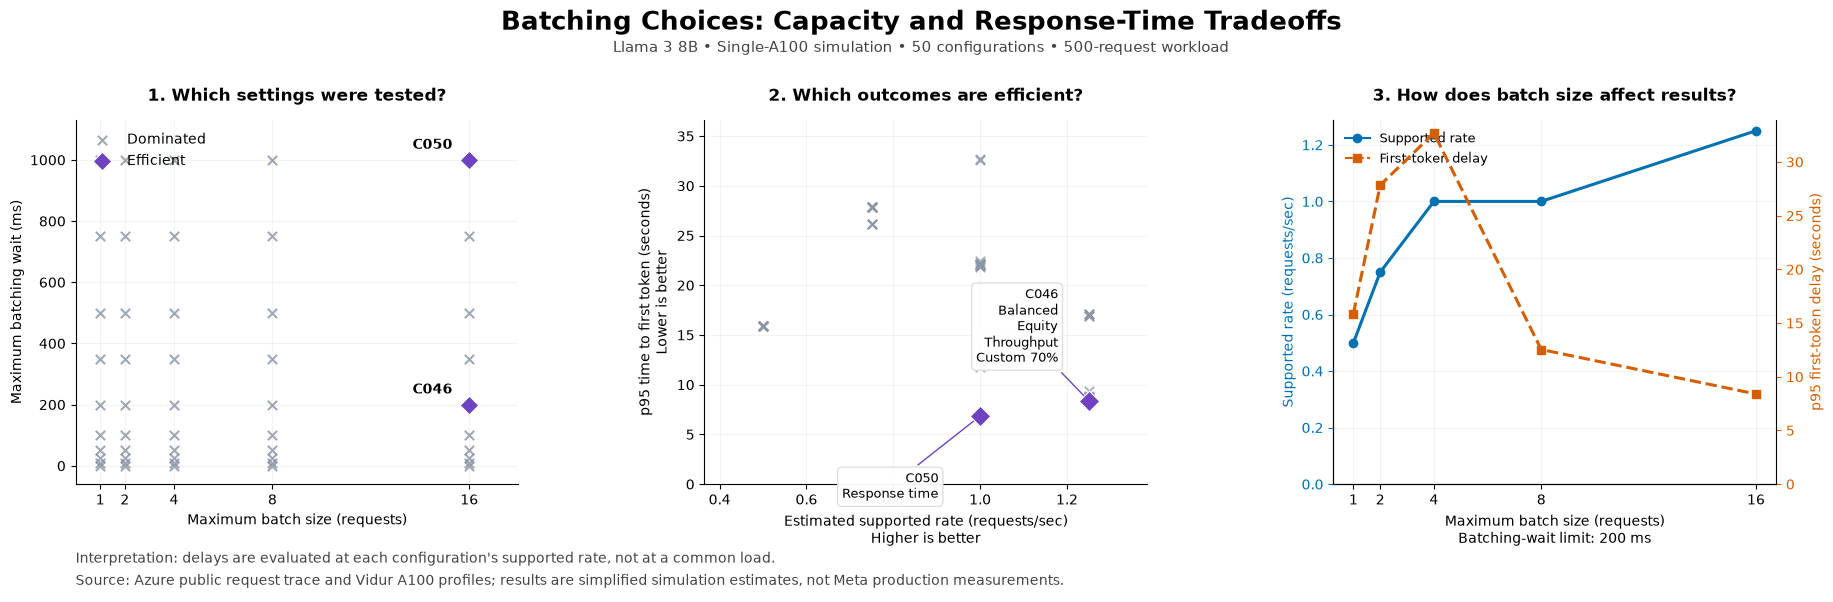

Saved: c:\Users\Isabelle\OneDrive - Fisher College\Meta_Inference_Optimization\images\optimization_tradeoffs.png


In [ ]:
from matplotlib.lines import Line2D

DOMINATED_COLOR = "#8A94A3"
FRONTIER_COLOR = "#6F42C1"
CAPACITY_COLOR = "#0072B2"
RESPONSE_COLOR = "#D55E00"

plot_df = results_df.copy()
plot_df["p95_ttft_seconds"] = plot_df[DELAY_COLUMN] / 1000

efficient = plot_df.loc[plot_df["is_pareto"]]
inefficient = plot_df.loc[~plot_df["is_pareto"]]

with plt.rc_context({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    fig, axes = plt.subplots(1, 3, figsize=(19, 6.5))
    fig.subplots_adjust(
        left=0.055, right=0.95, bottom=0.23, top=0.79, wspace=0.42
    )

    fig.suptitle(
        "Batching Choices: Capacity and Response-Time Tradeoffs",
        fontsize=19, fontweight="bold", y=0.96,
    )
    fig.text(
        0.5, 0.895,
        "Llama 3 8B • Single-A100 simulation • 50 configurations • "
        "500-request workload",
        ha="center", fontsize=11, color="#444444",
    )

    # Panel 1: decision space
    ax = axes[0]
    ax.scatter(
        inefficient["max_batch_size"], inefficient["max_wait_ms"],
        color=DOMINATED_COLOR, marker="x", s=45, alpha=0.8,
        label="Dominated", zorder=2,
    )
    ax.scatter(
        efficient["max_batch_size"], efficient["max_wait_ms"],
        color=FRONTIER_COLOR, marker="D", s=90,
        edgecolor="white", linewidth=0.8,
        label="Efficient", zorder=3,
    )

    for _, row in efficient.iterrows():
        ax.annotate(
            row["config_id"],
            (row["max_batch_size"], row["max_wait_ms"]),
            xytext=(-12, 8), textcoords="offset points",
            ha="right", fontsize=10, fontweight="bold",
        )

    ax.set_title("1. Which settings were tested?", pad=14)
    ax.set_xlabel("Maximum batch size (requests)")
    ax.set_ylabel("Maximum batching wait (ms)")
    ax.set_xticks(BATCH_SIZES)
    ax.set_xlim(0, 18)
    ax.set_ylim(-60, 1130)
    ax.legend(loc="upper left", frameon=False)
    ax.grid(alpha=0.15)

    # Panel 2: objective space
    ax = axes[1]
    ax.scatter(
        inefficient[RATE_COLUMN], inefficient["p95_ttft_seconds"],
        color=DOMINATED_COLOR, marker="x", s=45, alpha=0.7,
    )
    ax.scatter(
        efficient[RATE_COLUMN], efficient["p95_ttft_seconds"],
        color=FRONTIER_COLOR, marker="D", s=110,
        edgecolor="white", linewidth=0.8, zorder=4,
    )

    # Group strategy names when they select the same configuration.
    short_names = {
        "Balanced": "Balanced",
        "Equity": "Equity",
        "Throughput priority": "Throughput",
        "Response-time priority": "Response time",
        "Custom: 70% responsiveness": "Custom 70%",
    }

    for config_id, group in strategies_df.reset_index().groupby("config_id"):
        row = plot_df.loc[plot_df["config_id"].eq(config_id)].iloc[0]
        names = [short_names.get(name, name) for name in group["strategy"]]
        label = config_id + "\n" + "\n".join(names)

        # Position both labels above their points.
        offset = (-22, 25) if config_id == "C046" else (-45, 20)

        ax.annotate(
            label,
            (row[RATE_COLUMN], row["p95_ttft_seconds"]),
            xytext=offset, textcoords="offset points",
            ha="right", va="bottom",
            fontsize=9,
            arrowprops={"arrowstyle": "-", "color": FRONTIER_COLOR},
            bbox={
                "boxstyle": "round,pad=0.35",
                "fc": "white",
                "ec": "#DDDDDD",
                "alpha": 0.95,
            },
        )

    ax.set_title("2. Which outcomes are efficient?", pad=14)
    ax.set_xlabel("Estimated supported rate (requests/sec)\nHigher is better")
    ax.set_ylabel("p95 time to first token (seconds)\nLower is better")
    ax.set_ylim(0, plot_df["p95_ttft_seconds"].max() * 1.12)
    ax.margins(x=0.18)
    ax.grid(alpha=0.15)

    # Panel 3: batch-size relationship with batching wait held fixed
    fixed_wait = 200
    batch_slice = plot_df.loc[
        plot_df["max_wait_ms"].eq(fixed_wait)
    ].sort_values("max_batch_size")

    ax = axes[2]
    delay_axis = ax.twinx()

    ax.plot(
        batch_slice["max_batch_size"], batch_slice[RATE_COLUMN],
        color=CAPACITY_COLOR, marker="o", linewidth=2.2,
    )
    delay_axis.plot(
        batch_slice["max_batch_size"], batch_slice["p95_ttft_seconds"],
        color=RESPONSE_COLOR, marker="s", linestyle="--", linewidth=2.2,
    )

    ax.set_title("3. How does batch size affect results?", pad=14)
    ax.set_xlabel("Maximum batch size (requests)\nBatching-wait limit: 200 ms")
    ax.set_ylabel("Supported rate (requests/sec)", color=CAPACITY_COLOR)
    delay_axis.set_ylabel(
        "p95 first-token delay (seconds)", color=RESPONSE_COLOR
    )
    ax.tick_params(axis="y", colors=CAPACITY_COLOR)
    delay_axis.tick_params(axis="y", colors=RESPONSE_COLOR)
    delay_axis.spines["right"].set_visible(True)
    ax.set_xticks(BATCH_SIZES)
    ax.set_ylim(bottom=0)
    delay_axis.set_ylim(bottom=0)
    ax.grid(alpha=0.15)

    ax.legend(handles=[
        Line2D(
            [0], [0], color=CAPACITY_COLOR, marker="o",
            label="Supported rate",
        ),
        Line2D(
            [0], [0], color=RESPONSE_COLOR, marker="s",
            linestyle="--", label="First-token delay",
        ),
    ], loc="best", frameon=False, fontsize=9)

    fig.text(
        0.055, 0.075,
        "Interpretation: delays are evaluated at each configuration's supported "
        "rate, not at a common load.\n"
        "Source: Azure public request trace and Vidur A100 profiles; "
        "results are simplified simulation estimates, not Meta production measurements.",
        fontsize=10, color="#444444", linespacing=1.6,
    )

    figure_path = IMAGES_DIR / "optimization_tradeoffs.png"
    fig.savefig(
        figure_path, dpi=300, bbox_inches="tight", facecolor="white"
    )
    plt.show()

print("Saved:", figure_path)